In [25]:
import pandas as pd

#https://www.kaggle.com/datasets/anselerol/job-postings-and-resumes-with-embeddings-faiss?resource=download
df = pd.read_csv('../data/raw/resumes.csv')

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   id         2484 non-null   int64  
 1   text       2484 non-null   object 
 2   name       0 non-null      float64
 3   embedding  2484 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 77.8+ KB


In [3]:
df.head()

,id,text,name,embedding
0,1,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,NaN,"[-0.04447828233242035, 0.021229209378361702, 0..."
1,2,"HR SPECIALIST, US HR OPERATIONS ...",NaN,"[-0.05166391283273697, 0.01624675653874874, 0...."
2,3,HR DIRECTOR Summary Over 2...,NaN,"[-0.04784499853849411, 0.019322028383612633, -..."
3,4,HR SPECIALIST Summary Dedica...,NaN,"[-0.10490810126066208, 0.011350762099027634, 0..."
4,5,HR MANAGER Skill Highlights ...,NaN,"[-0.06549879908561707, 0.04003952443599701, -0..."


In [22]:
df.iloc[0]['text']

"         HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss pr

In [23]:
df.iloc[1]['text']

"         HR SPECIALIST, US HR OPERATIONS       Summary     Versatile  media professional with background in Communications, Marketing, Human Resources and Technology.\xa0        Experience     09/2015   to   Current     HR Specialist, US HR Operations    Company Name   －   City  ,   State       Managed communication regarding launch of Operations group, policy changes and system outages      Designed standard work and job aids to create comprehensive training program for new employees and contractors         Audited job postings for old, pending, on-hold and draft positions.           Audited union hourly, non-union hourly and salary background checks and drug screens             Conducted monthly new hire benefits briefing to new employees across all business units               Served as a link between HR Managers and vendors by handling questions and resolving system-related issues         Provide real-time process improvement feedback on key metrics and initiatives  Successfully r

In [11]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import ast  # Pour convertir les chaînes en listes si nécessaire

# Conversion des embeddings si stockés en chaîne
def convert_embedding(embedding_str):
    """Convertit une chaîne en liste numpy array"""
    if isinstance(embedding_str, str):
        return np.array(ast.literal_eval(embedding_str))
    elif isinstance(embedding_str, list):
        return np.array(embedding_str)
    else:
        return embedding_str

# Appliquer la conversion
df['embeddings_array'] = df['embedding'].apply(convert_embedding)

# Vérifier la dimension des embeddings
embedding_dim = len(df['embeddings_array'].iloc[0])
print(f"Dimension des embeddings : {embedding_dim}")

# Créer la matrice d'embeddings => c'est sur cette matrice qu'on va calculer les clusters
embeddings_matrix = np.vstack(df['embeddings_array'].values)
print(f"Shape de la matrice d'embeddings : {embeddings_matrix.shape}")

Dimension des embeddings : 384
Shape de la matrice d'embeddings : (2484, 384)


In [12]:
from sklearn.preprocessing import StandardScaler
# Normaliser les données
scaler = StandardScaler()
embeddings_matrix_normalized = scaler.fit_transform(embeddings_matrix)

In [13]:
pca = PCA(n_components=min(50, embedding_dim))#On prend le min entre 50 et embedding_dim
embeddings_reduced = pca.fit_transform(embeddings_matrix_normalized)
print(f"Variance expliquée par les {pca.n_components_} composantes : {pca.explained_variance_ratio_.sum():.2%}")

Variance expliquée par les 50 composantes : 65.77%


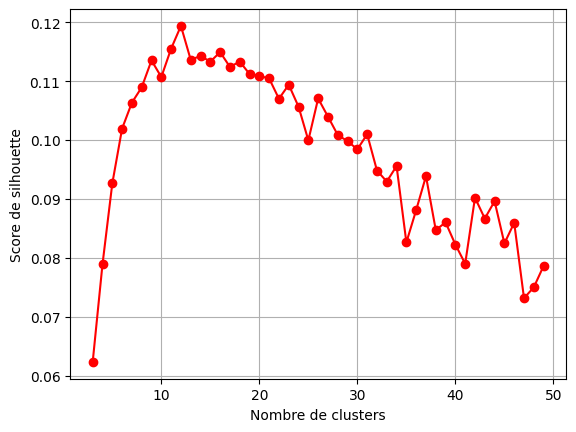

In [14]:
# 3. DÉTERMINATION DU NOMBRE OPTIMAL DE CLUSTERS (score de silhouette)
silhouette_scores = []
K_range = range(2, 50)  # Tester de 2 à 14 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(embeddings_reduced)
    #inertias.append(kmeans.inertia_)

    if k > 1:  # silhouette_score nécessite au moins 2 clusters
        score = silhouette_score(embeddings_reduced, kmeans.labels_)
        silhouette_scores.append(score)
    else:
        silhouette_scores.append(0)

plt.plot(K_range[1:], silhouette_scores[1:], 'ro-')
plt.xlabel('Nombre de clusters')
plt.ylabel('Score de silhouette')
plt.grid(True)
plt.show()

In [16]:
# 4. CLUSTERING AVEC K-MEANS (choisir k optimal)
optimal_k = 12  #Par exemple
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
cluster_labels = kmeans.fit_predict(embeddings_reduced)

df['cluster'] = cluster_labels

# 5. ANALYSE DES CLUSTERS
# Statistiques par cluster
cluster_stats = df.groupby('cluster').agg({
    'id': 'count',
    #'source': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'N/A',
    #'date': ['min', 'max']
}).round(2)

In [19]:
cluster_stats = cluster_stats.sort_values(by='id', ascending=False)  # si la colonne s'appelle 'title'
cluster_stats

,id
cluster,
4,322
5,296
3,285
9,260
11,256
1,255
10,200
6,167
2,143


In [21]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Télécharger les stop words français si nécessaire
nltk.download('stopwords')
english_stop_words = stopwords.words('english')

def extract_keywords_by_cluster(texts, labels, n_keywords=10):
    """Extrait les mots-clés TF-IDF par cluster"""
    unique_labels = np.unique(labels)
    keywords_by_cluster = {}

    for label in unique_labels:
        cluster_texts = [texts[i] for i in range(len(texts)) if labels[i] == label]

        if len(cluster_texts) < 2:
            keywords_by_cluster[label] = ["peu_de_documents"]
            continue

        # CRÉER UN NOUVEAU VECTORIZER POUR CHAQUE CLUSTER
        vectorizer = TfidfVectorizer(
            max_features=100,
            stop_words=english_stop_words,
            ngram_range=(2, 2),  # Bigrammes et trigrammes
            min_df=2,  # Mot doit apparaître dans au moins 2 docs du cluster
            max_df=0.1,  # Éliminer les mots trop fréquents
            token_pattern=r'(?u)\b[a-zA-ZÀ-ÿ]{6,}\b'  # Uniquement lettres, min 3 caractères
        )

        try:
            tfidf_matrix = vectorizer.fit_transform(cluster_texts)
            feature_names = vectorizer.get_feature_names_out()

            if len(feature_names) == 0:
                keywords_by_cluster[label] = ["aucun_mot"]
                continue

            tfidf_scores = tfidf_matrix.mean(axis=0).A1
            top_indices = tfidf_scores.argsort()[-n_keywords:][::-1]
            top_keywords = [feature_names[i] for i in top_indices]
            keywords_by_cluster[label] = top_keywords

        except Exception as e:
            keywords_by_cluster[label] = [f"erreur: {str(e)[:30]}"]

    return keywords_by_cluster

# Utiliser la colonne 'text' ou 'chunk_text' pour l'extraction
texts = df['text'].fillna('').astype(str).tolist()
keywords_by_cluster = extract_keywords_by_cluster(texts, cluster_labels, n_keywords=4)

print("\nMots-clés par cluster :")
for cluster in sorted(keywords_by_cluster.keys()):
    keywords = keywords_by_cluster[cluster]
    print(f"Cluster {cluster}: {', '.join(keywords)}")

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/khaledbouabdallah/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.



Mots-clés par cluster :
Cluster 0: problem solver, community service, excellent customer, physical education
Cluster 1: director business, quality assurance, representative company, analyst company
Cluster 2: public relations, customer satisfaction, leadership development, travel arrangements
Cluster 3: associate summary, administrative assistant, january january, experience associate
Cluster 4: engineering technician, engineering intern, january january, company responsible
Cluster 5: assistant company, director finance, decision making, accounts receivables
Cluster 6: classroom teacher, childhood education, august company, company august
Cluster 7: january company, assistant company, floral designer, professional experience
Cluster 8: ensure quality, institute america, company executive, associate science
Cluster 9: business development, company january, excellent customer, patient information
Cluster 10: public speaking, united states, january january, account manager
Cluster 11: s